In [1]:
# ── 1. Imports & connection ────────────────────────────────────────
import pandas as pd, matplotlib.pyplot as plt, geopandas as gpd
from sqlalchemy import create_engine, text

ENG = create_engine("postgresql://markfinlay:@localhost:5432/osm")
print("✅ Connected")

✅ Connected


In [7]:
# ── 2. Completeness counts: UK + IE merged ────────────────────────
sql_counts = """
WITH base AS (
  SELECT
    (surface IS NOT NULL) AS has_surface
  FROM planet_osm_line
  WHERE lower(highway) IN ('path','footway','track')
)
SELECT COUNT(*)                               AS total_ways,
       SUM(CASE WHEN has_surface THEN 1 END)  AS tagged_ways
FROM   base;
"""
df_cnt = pd.read_sql(sql_counts, ENG)
df_cnt["pct_tagged"] = 100 * df_cnt.tagged_ways / df_cnt.total_ways
display(df_cnt)

,total_ways,tagged_ways,pct_tagged
0,2791418,837720,30.010554


In [8]:
sql_top15 = """
SELECT surface, COUNT(*) AS n
FROM planet_osm_line
WHERE lower(highway) IN ('path','footway','track')
  AND surface IS NOT NULL
GROUP BY surface
ORDER BY n DESC
LIMIT 15;
"""
df_top15 = pd.read_sql(sql_top15, ENG)
display(df_top15)

,surface,n
0,asphalt,296421
1,paved,77501
2,dirt,75690
3,paving_stones,74839
4,grass,71989
5,gravel,52696
6,ground,50365
7,unpaved,39513
8,concrete,35015
9,compacted,26543


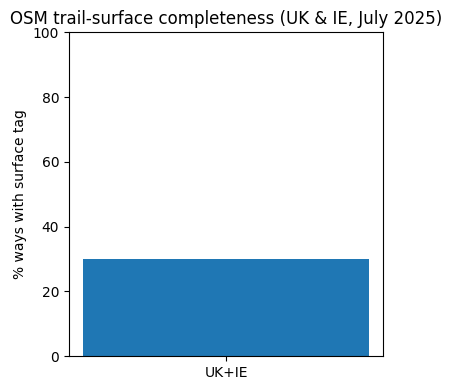

In [10]:
latex_table = df_top15.to_latex(index=False, caption="Top-15 raw \\texttt{surface=*} values in UK+IE extract.",
                                label="tab:osm-surface-top15")
print(latex_table)

\begin{table}
\caption{Top-15 raw \texttt{surface=*} values in UK+IE extract.}
\label{tab:osm-surface-top15}
\begin{tabular}{lr}
\toprule
surface & n \\
\midrule
asphalt & 296421 \\
paved & 77501 \\
dirt & 75690 \\
paving_stones & 74839 \\
grass & 71989 \\
gravel & 52696 \\
ground & 50365 \\
unpaved & 39513 \\
concrete & 35015 \\
compacted & 26543 \\
wood & 9376 \\
fine_gravel & 6727 \\
sett & 2656 \\
sand & 2335 \\
earth & 2277 \\
\bottomrule
\end{tabular}
\end{table}

